# Exercise 1: Classification with FFNN, LSTM, and GRU

---

## Introduction

In this exercise, you will learn how to use Long Short-Term Memory (LSTM) and Gated Recurrent Units (GRU) for text classification on the IMDB dataset, which consists of movie reviews labeled as positive or negative. You will compare the performance of these models with a Feed-Forward Neural Network (FFNN) on this classification task. Specifically, you will clean the dataset, explore its statistics, and select appropriate parameters. Afterward, you will train and evaluate each model, calculating their precision, and finally compare the results to determine which model performs best for this particular task.

## Theoretical Background

### Recurrent Neural Networks (RNN)
RNNs are neural networks designed to work with sequential data. The basic RNN formula is:

$$ h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b_h) $$

$$ y_t = W_{hy}h_t + b_y $$

Where:
- $h_t$ is the hidden state at time $t$
- $x_t$ is the input at time $t$
- $W_{xh}, W_{hh}, W_{hy}$ are weight matrices
- $b_h, b_y$ are bias vectors

### Long Short-Term Memory (LSTM)
LSTM networks solve the vanishing gradient problem by introducing gates. Each gate plays a specific role in controlling the flow of information:

- **Forget Gate ($f_t$):**
  $$ f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f) $$  
  The forget gate determines how much information from the previous cell state $C_{t-1}$ should be "forgotten." If $f_t$ is close to 1, the information is retained; if close to 0, it is discarded.

- **Input Gate ($i_t$):**
  $$ i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i) $$  
  The input gate decides how much new information from the candidate cell state $\tilde{C}_t$ should be added to the cell state. This gate ensures that only relevant updates are applied.

- **Candidate Cell State ($\tilde{C}_t$):**
  $$ \tilde{C}_t = \tanh(W_C \cdot [h_{t-1}, x_t] + b_C) $$  
  Represents the potential new content to be added to the cell state, modulated by the input gate.

- **Cell State Update ($C_t$):**
  $$ C_t = f_t * C_{t-1} + i_t * \tilde{C}_t $$  
  Combines the retained information from the forget gate and the new content from the input gate to update the cell state.

- **Output Gate ($o_t$):**
  $$ o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o) $$  
  Determines how much of the cell state $C_t$ should be exposed as the hidden state $h_t$.

- **Hidden State Update ($h_t$):**
  $$ h_t = o_t * \tanh(C_t) $$  
  Combines the output gate with the transformed cell state to produce the next hidden state.

### Gated Recurrent Unit (GRU)
GRU is a simplified version of LSTM that combines some gates and eliminates the explicit cell state. Its gates serve the following purposes:

- **Update Gate ($z_t$):**
  $$ z_t = \sigma(W_z \cdot [h_{t-1}, x_t]) $$  
  Controls how much of the past information ($h_{t-1}$) should be carried forward to the next hidden state. It acts as a combination of LSTM's forget and input gates.

- **Reset Gate ($r_t$):**
  $$ r_t = \sigma(W_r \cdot [h_{t-1}, x_t]) $$  
  Determines how much of the previous hidden state ($h_{t-1}$) should be ignored while calculating the candidate hidden state $\tilde{h}_t$. This gate allows the model to focus on new input and selectively "reset" memory.

- **Candidate Hidden State ($\tilde{h}_t$):**
  $$ \tilde{h}_t = \tanh(W \cdot [r_t * h_{t-1}, x_t]) $$  
  Represents the proposed new state based on the current input and the selectively reset past state.

- **Hidden State Update ($h_t$):**
  $$ h_t = (1 - z_t) * h_{t-1} + z_t * \tilde{h}_t $$  
  Combines the retained past information (scaled by $(1 - z_t)$) and the candidate state (scaled by $z_t$) to produce the next hidden state.

### Key Differences between LSTM and GRU
1. **State Variables:** LSTM has both a cell state and a hidden state, while GRU has only a hidden state.  
2. **Gates:** LSTM uses three gates (forget, input, output), while GRU uses two gates (reset and update).  
3. **Efficiency:** GRU is computationally more efficient due to its simpler structure but may not handle long sequences as effectively as LSTM.

## Tasks

### Task 1: Prepare the Dataset
1. Load the IMDB dataset and the stemming dictionary into your environment.
2. The imdb preprocessing code is provided just execute the preprocessing:
   - Convert all text to lowercase.
   - Remove special characters and stop words.
   - Split the data into training, validation, and test sets.



   
### Task 2: Explore Dataset Statistics
1. Analyze the dataset to understand the distribution of reviews (e.g., number of reviews, lengths of reviews, number of unique words, etc.).
2. Complete the code by doing as follow:
  - What value will you set for the `vocab_size` (the maximum number of words to keep in the tokenizer’s vocabulary)? Specify the vocabulary size when initializing the tokenizer.
  - Pad the sequences so they all have the same length.
    - What padding strategy will you use? Will you pad at the **beginning** or the **end** of the sequences? (Hint: check the `padding` argument in the `pad_sequences` function.)
    - What index will be used for the padding token?
  - Create input-output pairs for training and testing.
  - Apply `texts_to_sequences` on the sentence: "Samir and Ali have been working very hard."
  - What is the result of applying `texts_to_sequences` to this sentence?
  - How many unknown words (out-of-vocabulary) are there in the sentence?
  - What index do the out-of-vocabulary words get (if there are any)?
  - What happens if we add an OOV token `<oov>` when initializing the tokenizer?  
  - Perform this step and then apply `texts_to_sequences` to the previous sentence. What index did the token `<oov>` get?
  
   
   
### Task 3: Train the Models
1. Implement and train three models:
   - **Feed-Forward Neural Network (FFNN)**
   - **LSTM-based model**
   - **GRU-based model**
   
2. Evaluate the models using precision, recall, fscore. Compare the results to determine which model performs the best.

### Task 4: Hyperparameter Tuning
1. Tune the hyperparameters for each model (e.g., number of layers, number of units, learning rate, batch size) to optimize their performance.

### Task 5: Compare and Conclude
1. After training and evaluating the models, compare their precision scores.
2. Draw conclusions about the relative performance of FFNN, LSTM, and GRU on the IMDB sentiment analysis task.


### Extra Work (Optional)

For a deeper exploration of word embeddings and their impact on sequence models, follow these steps:

1. **Train a Word2Vec Model:**
   - Use the `gensim` library to train a Word2Vec model on the IMDB dataset and a provided corpus "TED2013.ar-en.en".
   - The combined dataset will ensure a richer and more generalized set of word embeddings.
   - Save the resulting embeddings using a pre-trained format (`.bin` or `.txt`).

   **Hints:**
   - Preprocess the text exactly in the same way you did earlier (e.g., tokenization, cleaning).
   - Save the model using `model.wv.save_word2vec_format('embeddings.txt')`.

2. **Use the Word2Vec Embeddings in Your LSTM and GRU Models:**
    - Initialize the Embedding Layer with Pretrained Word2Vec Embeddings

    - When initializing the embedding layer in your LSTM and GRU models, you need to replace each word in the embedding layer by its corresponding trained word vector, if it is found in the pretrained Word2Vec model.
    - For any word in the vocabulary that does **not** exist in the pretrained embeddings, you should leave the corresponding entry as **zeroes** in the embedding matrix.

    - This way, you can create an **embedding matrix** where each word in your vocabulary is mapped to its corresponding word vector, and unknown words are represented by vectors of zeros.

    ### Code Snippet:

    ```python
    embedding_matrix = np.zeros((max_vocab_size, embedding_dim))

    for word, i in tokenizer.word_index.items():
        if i < max_vocab_size:
            try:
                embedding_vector = word2vec_model.wv[word]  # Find the pretrained embedding
                embedding_matrix[i] = embedding_vector  # Assign it to the embedding matrix
            except KeyError:
                embedding_matrix[i] = np.zeros(embedding_dim)  # Assign zero vector if word is not found
    ```
    - Then, in your model you will have something like:
    ```python
    model_lstm = Sequential()
    model_lstm.add(Embedding(input_dim=max_vocab_size, output_dim=embedding_dim, weights=[embedding_matrix], input_length=max_len, trainable=False))  # Static embeddings
    ```
   - Create two setups for the embedding layer:
     - **Static Embeddings:** Keep the embedding weights fixed during training.
     - **Dynamic Embeddings:** Allow the embedding weights to be updated during training.

   **Hints:**
   - Use TensorFlow/Keras to create an embedding matrix matching the size of your vocabulary.
   - For static embeddings, set the `trainable` parameter of the `Embedding` layer to `False`.
   - For dynamic embeddings, set `trainable=True`.

3. **Compare Results:**
   - Train the LSTM and GRU models using the Word2Vec embeddings (static and dynamic) and compare their performance.
   - Compare these results with the baseline models where embeddings were learned from scratch by the LSTM or GRU.

   **What to Observe:**
   - How does using pre-trained embeddings affect model performance (precision, recall, F1-score)?
   - Does allowing embeddings to update dynamically provide a significant improvement over static embeddings?

By completing this extra task, you will gain practical insights into the role of pre-trained embeddings in improving the performance of sequence models and their applicability in transfer learning scenarios.


In [2]:
!apt-get install unrar
!unrar x Lab7_data.rar
!ls

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:6.1.5-1ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 41 not upgraded.

UNRAR 6.11 beta 1 freeware      Copyright (c) 1993-2022 Alexander Roshal


Extracting from Lab7_data.rar

Creating    EN-AR_Translit                                            OK
Extracting  EN-AR_Translit/dev.ar                                          0%  OK 
Extracting  EN-AR_Translit/dev.en                                          0%  OK 
Extracting  EN-AR_Translit/test.ar                                         0%  OK 
Extracting  EN-AR_Translit/test.en                                         0%  OK 
Extracting  EN-AR_Translit/train.ar                                        1%  OK 
Extracting  EN-AR_Translit/train.en                                        2%  OK 
Extracting  defaultdict_stemming.json            

In [1]:
!pip install nltk
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Rosey\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True


IMDB Dataset Dataset Statistics:
Number of instances per class:
label
1    25000
0    25000
Name: count, dtype: int64
Average number of words per review: 89.69
Vocabulary size: 83539



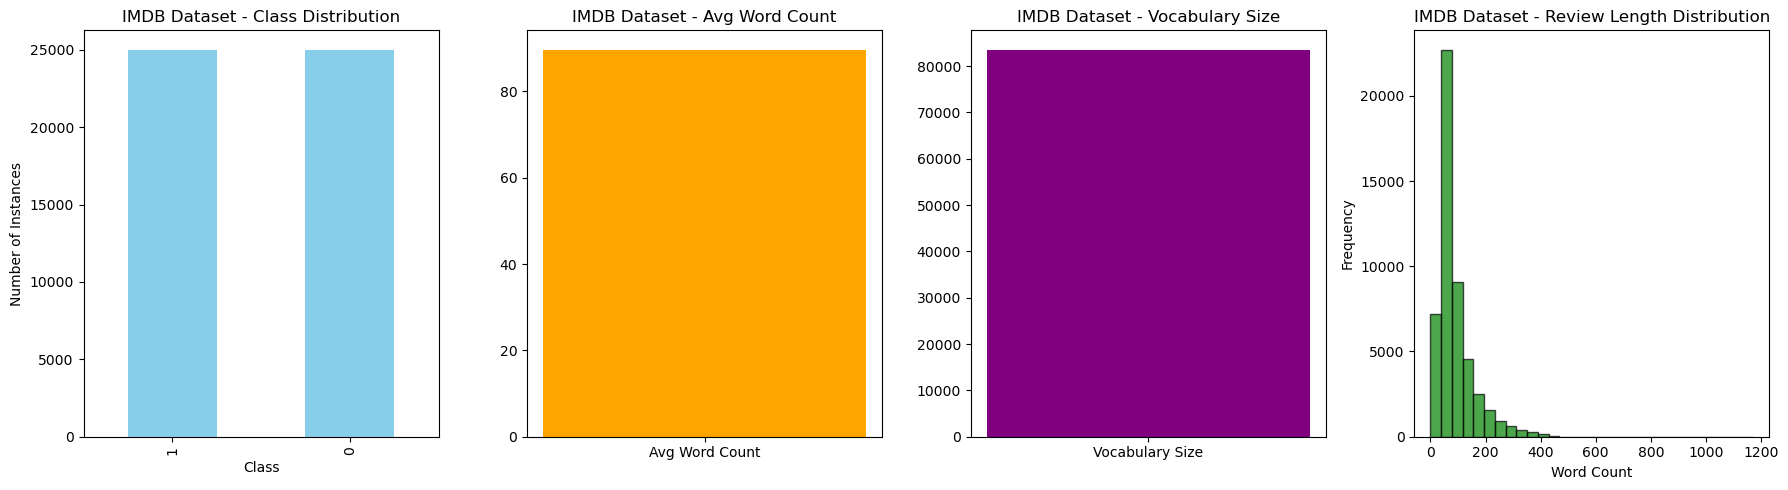

In [2]:
import numpy as np
import pandas as pd
import re
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, LSTM, GRU, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import GlobalAveragePooling1D
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from collections import defaultdict
import matplotlib.pyplot as plt
import json

# -------------------------------------------------------
# Create dictionary mapping stopwords -> True for fast lookup
# -------------------------------------------------------
stop_words_dict = defaultdict(bool)
for w in set(stopwords.words('english')):
    stop_words_dict[w.lower()] = True



# =======================================================
# 1. TEXT PREPROCESSING FUNCTION
# =======================================================

def preprocess_text(text, stem=False, stemmer=None, stemming_dict=None):
    """
    Clean and preprocess raw text by removing HTML tags, lowercasing,
    removing stopwords, keeping only alphabetic tokens, and optionally applying stemming.

    Parameters:
    text (str): Input text to preprocess.
    stem (bool): Whether to apply stemming. Default False.
    stemmer (object): Stemming algorithm instance (e.g., PorterStemmer). Required if stem=True.
    stemming_dict (dict): Optional dictionary mapping words -> stemmed forms.

    Returns:
    str: Cleaned, preprocessed text.

    Notes:
    - HTML tags are removed using regex.
    - Non-alphabetic tokens and stopwords are removed.
    - Stemming is optional and can use a custom dictionary.
    """
    # 1. Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    
    # 2. Convert to lowercase
    text = text.lower()
    
    # 3. Split and filter
    tokens = [word for word in text.split() 
              if word.isalpha() and not stop_words_dict[word]]
    
    # 4. Apply stemming if requested
    if stem and stemmer:
        if stemming_dict:
            tokens = [stemming_dict.get(word, stemmer.stem(word)) for word in tokens]
        else:
            tokens = [stemmer.stem(word) for word in tokens]
    
    # 5. Return joined string
    return ' '.join(tokens)



def load_stemming_dict(file_path):
    """
    Load a custom stemming dictionary from a JSON file.

    Parameters:
    file_path (str): Path to the JSON file containing word→stem mappings.

    Returns:
    dict: The loaded custom stemming dictionary.

    Notes:
    - Useful when you want consistent stemming across datasets.
    """
    with open(file_path, 'r') as file:
        stemming_dict = json.load(file)

    print(f"Stemming dictionary loaded from {file_path}")
    return stemming_dict



# =======================================================
# 2. DATASET LOADING + PREPROCESSING
# =======================================================

def load_and_preprocess_dataset(dataset_path, preprocess=False, stem=False, stemming_dict_file="defaultdict_stemming.json"):
    """
    Load the dataset from a CSV file and apply optional preprocessing steps.

    Parameters:
    dataset_path (str): Path to the CSV file.
    preprocess (bool): If True, applies text preprocessing.
    stem (bool): If True, uses stemming.
    stemming_dict_file (str): File path for custom stemming dictionary.

    Returns:
    pandas.DataFrame: A DataFrame containing columns 'text' and 'label'.

    Workflow:
    1. Load IMDB dataset and rename columns.
    2. Convert labels: positive → 1, negative → 0.
    3. Apply preprocessing if requested.
    """
    # 1. Load IMDB dataset with standardized column names
    if 'IMDB_Dataset.csv' in dataset_path:
        dataset = pd.read_csv(dataset_path, usecols=['review', 'sentiment'])
        dataset = dataset.rename(columns={'review': 'text', 'sentiment': 'label'})

        # Convert 'positive'/'negative' → 1/0
        dataset['label'] = dataset['label'].apply(lambda x: 1 if x == 'positive' else 0)
    else:
        raise ValueError("Invalid dataset path. Please provide the correct path.")

    # 2. Apply optional preprocessing
    if preprocess:
        if stem:
            # Load custom dictionary + create stemmer object
            stemming_dict = load_stemming_dict(stemming_dict_file)
            stemmer = PorterStemmer()
        else:
            stemming_dict = None
            stemmer = None

        # Apply preprocessing to each text entry
        dataset['text'] = dataset['text'].apply(
            lambda x: preprocess_text(
                x,
                stem=stem,
                stemmer=stemmer,
                stemming_dict=stemming_dict
            )
        )

    return dataset



# =======================================================
# 3. TRAIN/TEST SPLIT FUNCTION
# =======================================================

def split_data(dataset, test_size=0.2, random_state=42):
    """
    Split the dataset into training and testing subsets.

    Parameters:
    dataset (pandas.DataFrame): Dataset containing 'text' and 'label'.
    test_size (float): Fraction of dataset to use for testing.
    random_state (int): Seed for reproducibility.

    Returns:
    tuple: (X_train, X_test, y_train, y_test)
    """
    # Use sklearn's train_test_split
    X_train, X_test, y_train, y_test = train_test_split(
        dataset['text'],
        dataset['label'],
        test_size=test_size,
        random_state=random_state
    )
    return X_train, X_test, y_train, y_test



# =======================================================
# 4. DATASET STATISTICS & VISUALIZATION
# =======================================================

def display_statistics(dataset, dataset_name):
    """
    Display descriptive statistics and visualizations for the dataset.

    Parameters:
    dataset (pandas.DataFrame): The dataset to analyze.
    dataset_name (str): Name used for labeling plots.

    Output:
    - Prints:
      * Class distribution
      * Average review length
      * Vocabulary size
    - Visualizes:
      * Class distribution
      * Average word count
      * Vocabulary size
      * Histogram of word count per review
    """
    # 1. Count number of examples per label
    class_counts = dataset['label'].value_counts()

    # 2. Compute number of words per review
    dataset['word_count'] = dataset['text'].apply(lambda x: len(x.split()))
    avg_word_count = dataset['word_count'].mean()

    # 3. Compute vocabulary size
    vocabulary = set(
        word for text in dataset['text'] for word in text.split()
    )
    vocab_size = len(vocabulary)

    # 4. Word count distribution for histogram
    word_count_distribution = dataset['word_count']

    # --- PRINTING STATISTICS ---
    print(f"\n{dataset_name} Dataset Statistics:")
    print(f"Number of instances per class:\n{class_counts}")
    print(f"Average number of words per review: {avg_word_count:.2f}")
    print(f"Vocabulary size: {vocab_size}\n")

    # --- VISUALIZATIONS ---
    plt.figure(figsize=(18, 5))

    # Bar chart: class distribution
    plt.subplot(1, 4, 1)
    class_counts.plot(kind='bar', color='skyblue')
    plt.title(f"{dataset_name} - Class Distribution")
    plt.xlabel("Class")
    plt.ylabel("Number of Instances")

    # Bar chart: average word count
    plt.subplot(1, 4, 2)
    plt.bar(["Avg Word Count"], [avg_word_count], color='orange')
    plt.title(f"{dataset_name} - Avg Word Count")

    # Bar chart: vocabulary size
    plt.subplot(1, 4, 3)
    plt.bar(["Vocabulary Size"], [vocab_size], color='purple')
    plt.title(f"{dataset_name} - Vocabulary Size")

    # Histogram: review length distribution
    plt.subplot(1, 4, 4)
    plt.hist(word_count_distribution, bins=30, color='green', alpha=0.7, edgecolor='black')
    plt.title(f"{dataset_name} - Review Length Distribution")
    plt.xlabel("Word Count")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()



# =======================================================
# 5. LOAD, PREPROCESS & SPLIT DATASET
# =======================================================

# Load dataset with preprocessing enabled (stemming disabled here)
imdb_df = load_and_preprocess_dataset(
    'IMDB_Dataset.csv',
    preprocess=True,
    stem=False
)

# Display dataset statistics and visualizations
display_statistics(imdb_df, "IMDB Dataset")

# Train/test split
X_train_imdb, X_test_imdb, y_train_imdb, y_test_imdb = split_data(imdb_df)


In [3]:
# =======================================================
# TOKENIZE AND PAD SEQUENCES
# =======================================================

def prepare_data_for_model(X_train, X_test, y_train, y_test, max_words=5000, max_len=50):
    """
    Prepare text and label data for input into Keras models by tokenizing,
    converting words to integer sequences, and padding sequences to equal length.

    Parameters:
    X_train, X_test (pd.Series):
        Raw text data for training and testing.
    y_train, y_test (pd.Series):
        Labels corresponding to each text sample.
    max_words (int):
        Maximum vocabulary size to keep based on word frequency (default 5000).
        Words outside this top-n list will be ignored.
    max_len (int):
        Fixed sequence length to pad or truncate sequences to (default 50).

    Returns:
    tuple:
        (X_train_padded, X_test_padded, y_train, y_test)
        - X_train_padded (numpy array): Tokenized + padded integer sequences (train set)
        - X_test_padded  (numpy array): Tokenized + padded integer sequences (test set)
        - y_train, y_test (numpy arrays): Converted label arrays

    Workflow:
    1. Create a Keras Tokenizer that keeps only the top `max_words` most frequent words.
    2. Fit tokenizer on training text (builds word-index mapping).
    3. Convert raw text into integer sequences using tokenizer.
    4. Pad sequences to uniform length (`max_len`) so all inputs are same size.
    5. Convert labels into numpy arrays for model compatibility.

    Example:
    Input:
        X_train = ["I love this movie", "This was awful"]
    Output:
        X_train_padded = [[1, 4, 7, 12], [8, 19, 63, 0]]
    """
    # ------------------------------------------------------
    # 1. Initialize Keras Tokenizer
    #    num_words limits vocabulary to most frequent `max_words`
    # ------------------------------------------------------
    tokenizer = Tokenizer(num_words=max_words)

    # ------------------------------------------------------
    # 2. Fit tokenizer on training text
    #    This learns word frequencies and builds word_index
    # ------------------------------------------------------
    tokenizer.fit_on_texts(X_train)

    # ------------------------------------------------------
    # 3. Convert text samples to integer sequences
    #    Each word is replaced with its index in tokenizer.word_index
    # ------------------------------------------------------
    X_train_seq = tokenizer.texts_to_sequences(X_train)
    X_test_seq = tokenizer.texts_to_sequences(X_test)

    # ------------------------------------------------------
    # 4. Pad/truncate sequences to fixed length `max_len`
    #    padding='pre' adds zeros at the beginning if sequence is too short
    # ------------------------------------------------------
    X_train_padded = pad_sequences(X_train_seq, maxlen=max_len, padding='pre')
    X_test_padded = pad_sequences(X_test_seq, maxlen=max_len, padding='pre')
    

    # ------------------------------------------------------
    # 5. Convert labels to numpy arrays
    # ------------------------------------------------------
    y_train_array = np.array(y_train)
    y_test_array = np.array(y_test)

    return X_train_padded, X_test_padded, y_train_array, y_test_array


# =======================================================
# APPLY TOKENIZATION AND PADDING TO IMDB DATASET
# =======================================================

max_words_imdb = 20000   # Maximum vocabulary size
max_len_imdb = 250       # Max sequence length

# Prepare IMDB data for model input
X_train_imdb_padded, X_test_imdb_padded, y_train_imdb_padded, y_test_imdb_padded = prepare_data_for_model(
    X_train_imdb,
    X_test_imdb,
    y_train_imdb,
    y_test_imdb,
    max_words=max_words_imdb,
    max_len=max_len_imdb
)

# Print sample outputs for verification
print(X_train_imdb_padded.shape, y_train_imdb_padded.shape)
print(X_train_imdb_padded[0])    # Example tokenized/padded sequence
print(y_train_imdb_padded[0])    # Corresponding label
print("\n\n")


(40000, 250) (40000,)
[    0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0   492
  1605    23  1738  6660   690  5205 17790  5339    13   623    22    26
  1022  1713   925   303   417   716   309    90  2421  4704  2793   120
    11    43  3127   140    87     8     3 12270    21   275    87   216
  9793    30 11969   225    31    41   283  9601  5905   207 14189  1690
   302   137   658  3648    9

In [4]:
# 5. Build Models

def build_ffnn(max_words, max_len, number_neurons, dropout, learning_rate):
    """
    Build a Feed-Forward Neural Network (FFNN) for text classification using averaged word embeddings.

    This model converts each word into a dense vector (Embedding layer),
    averages all word vectors to produce a fixed-size sentence representation,
    and passes it through fully-connected layers for binary classification.

    Parameters:
    max_words (int): Size of the vocabulary (number of unique tokens in dataset).
    max_len (int): Maximum sequence length after padding/truncation.
    number_neurons (int): Number of embedding dimensions AND dense layer neurons.
    dropout (float): Dropout rate applied to prevent overfitting.
    learning_rate (float): Learning rate for the Adam optimizer.

    Returns:
    Sequential: A compiled FFNN model ready for training.
    """
    model = Sequential([
        # 1. Embedding layer maps each word index to a dense vector of size `number_neurons`
        #    Input: (batch_size, max_len)
        #    Output: (batch_size, max_len, number_neurons)
         Embedding(input_dim=max_words, output_dim=number_neurons, input_length=max_len),


        # 2. Average all word embeddings along the sequence dimension
        #    Converts (batch_size, max_len, number_neurons) -> (batch_size, number_neurons)

        GlobalAveragePooling1D(),

        # 3. Fully-connected layer to learn nonlinear relationships in the averaged embeddings
        Dense(number_neurons, activation='relu'),


        # 4. Dropout layer to prevent overfitting by randomly deactivating neurons
        Dropout(dropout),


        # 5. Final output layer for binary classification (sigmoid → outputs probability)
        
        Dense(1, activation='sigmoid')

    ])

    # Compile model with Adam optimizer and binary cross-entropy loss
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model



def build_lstm(max_words, max_len, number_neurons, dropout, learning_rate):
    """
    Build an LSTM (Long Short-Term Memory) model for sequence classification.

    This model embeds each word, processes the sequence using an LSTM layer to
    capture long-range dependencies, and outputs a probability for binary classification.

    Parameters:
    max_words (int): Size of vocabulary.
    max_len (int): Maximum length of input sequences.
    number_neurons (int): Number of LSTM units (hidden state size).
    dropout (float): Dropout applied inside the LSTM unit.
    learning_rate (float): Learning rate for the Adam optimizer.

    Returns:
    Sequential: A compiled LSTM model ready for training.
    """
    model = Sequential([
        # 1. Embedding layer: converts token indices into dense vectors
        Embedding(input_dim=max_words, output_dim=number_neurons, input_length=max_len),

        # 2. LSTM layer: processes sequence step-by-step and captures temporal patterns
        #    dropout applies regularization to input connections
        LSTM(units=number_neurons, dropout=dropout),

        # 3. Output layer: predicts class probability
        Dense(1, activation='sigmoid')

    ])

    # Compile with Adam optimizer + binary classification loss
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model



def build_gru(max_words, max_len, number_neurons, dropout, learning_rate):
    """
    Build a GRU (Gated Recurrent Unit) model for sequence classification.

    GRUs are similar to LSTMs but more computationally efficient
    while still capturing long-term dependencies in sequences.

    Parameters:
    max_words (int): Size of vocabulary.
    max_len (int): Length of padded input sequences.
    number_neurons (int): Number of GRU units (hidden state size).
    dropout (float): Dropout applied to input connections inside the GRU.
    learning_rate (float): Learning rate for the optimizer.

    Returns:
    Sequential: A compiled GRU model ready for training.
    """
    model = Sequential([
        # 1. Embedding layer to map token IDs to dense vectors

        Embedding(input_dim=max_words, output_dim=number_neurons, input_length=max_len),
        # 2. GRU layer to process sequences and capture context
        GRU(units=number_neurons, dropout=dropout),

        # 3. Output layer for binary classification (probability output)
        Dense(1, activation='sigmoid')
    ])

    # Compile model
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model



def print_model_architecture(model, input_shape):
    """
    Print a detailed summary of the model architecture, including layer types,
    output shapes, and number of trainable parameters.

    Parameters:
    model (Sequential): The model to summarize.
    input_shape (tuple): Shape of the model input (batch_size, sequence_length).

    Returns:
    None
    """
    # 1. Build the model with the given input shape so Keras can infer layer sizes
    model.build(input_shape)

    # 2. Print header
    print("Model Architecture:")
    print("=" * 40)

    # 3. Display Keras' built-in summary (layers, params, shapes)
    model.summary()

    print("=" * 40 + "\n\n")



# ================================
# EXAMPLE USAGE
# ================================

number_neurons = 128
dropout = 0.4
learning_rate = 0.001

# 1. Build FFNN model for IMDB dataset
ffnn_imdb = build_ffnn(max_words_imdb, max_len_imdb, number_neurons, dropout, learning_rate)

# 2. Show embedding layer parameter count formula
print(f"Embedding Layer Weights: max_words_imdb: {max_words_imdb} * number_neurons: {number_neurons} = {max_words_imdb * number_neurons} parameters")

# 3. Print FFNN architecture
print_model_architecture(ffnn_imdb, input_shape=(None, max_len_imdb))


# LSTM model
lstm_imdb = build_lstm(max_words_imdb, max_len_imdb, number_neurons, dropout, learning_rate)
print(f"Input to LSTM: {max_words_imdb} * {number_neurons} = {max_words_imdb * number_neurons}")
print_model_architecture(lstm_imdb, input_shape=(None, X_train_imdb_padded.shape[1]))


# GRU model
gru_imdb = build_gru(max_words_imdb, max_len_imdb, number_neurons, dropout, learning_rate)
print(f"Input to GRU: {max_words_imdb} * {number_neurons} = {max_words_imdb * number_neurons}")
print_model_architecture(gru_imdb, input_shape=(None, X_train_imdb_padded.shape[1]))


Embedding Layer Weights: max_words_imdb: 20000 * number_neurons: 128 = 2560000 parameters
Model Architecture:


c:\Users\Rosey\anaconda3\envs\NLP\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,576,641 (9.83 MB)

 Trainable params: 2,576,641 (9.83 MB)

... (9 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 250, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 128)            │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,659,201 (10.14 MB)

 Trainable params: 2,659,201 (10.14 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# =======================================================
# 5. TRAIN AND EVALUATE MODELS
# =======================================================

def evaluate_model(model, X_test, y_test):
    """
    Evaluate a trained Keras model using accuracy, classification report,
    and confusion matrix metrics.

    Parameters:
    model (Sequential):
        The trained Keras model to evaluate.
    X_test (np.array):
        Test features (tokenized + padded sequences).
    y_test (np.array):
        True labels for the test set.

    Returns:
    None
        Prints evaluation metrics directly.

    Workflow:
    1. Use model.predict() to generate prediction probabilities.
    2. Convert probabilities to binary predictions using threshold 0.5.
    3. Print:
        - Accuracy score
        - Classification report (precision, recall, F1)
        - Confusion matrix
    """
    # ------------------------------------------------------
    # 1. Get predicted probabilities from the model
    #    model.predict returns floats in [0, 1]
    # ------------------------------------------------------
    y_pred_prob = model.predict(X_test)

    # ------------------------------------------------------
    # 2. Convert probabilities to binary class predictions
    #    > 0.5 → class 1, else class 0
    # ------------------------------------------------------
    y_pred = (y_pred_prob > 0.5).astype("int32")

    # ------------------------------------------------------
    # 3. Print evaluation metrics
    # ------------------------------------------------------
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))



# =======================================================
# TRAINING CONFIGURATION
# =======================================================
epochs = 2
batch_size = 128



# =======================================================
# TRAIN & EVALUATE EACH MODEL
# Remove comments to run training
# =======================================================

# -------------------------------------------------------
# Train & evaluate Feed-Forward Neural Network (FFNN)
# -------------------------------------------------------
print("Training FFNN on IMDB data...")
ffnn_imdb.fit(
    X_train_imdb_padded,
    y_train_imdb_padded,
    epochs=epochs,
    batch_size=batch_size,
    verbose=1
)
evaluate_model(ffnn_imdb, X_test_imdb_padded, y_test_imdb_padded)


# -------------------------------------------------------
# Train & evaluate LSTM model
# -------------------------------------------------------
print("Training LSTM on IMDB data...")
lstm_imdb.fit(
    X_train_imdb_padded,
    y_train_imdb_padded,
    epochs=epochs,
    batch_size=batch_size,
    verbose=1
)
evaluate_model(lstm_imdb, X_test_imdb_padded, y_test_imdb_padded)


# -------------------------------------------------------
# Train & evaluate GRU model
# -------------------------------------------------------
print("Training GRU on IMDB data...")
gru_imdb.fit(
    X_train_imdb_padded,
    y_train_imdb_padded,
    epochs=epochs,
    batch_size=batch_size,
    verbose=1
)
evaluate_model(gru_imdb, X_test_imdb_padded, y_test_imdb_padded)


Training FFNN on IMDB data...
Epoch 1/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.6843 - loss: 0.5662
Epoch 2/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.8473 - loss: 0.3505
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy: 0.87
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.91      0.87      4961
           1       0.90      0.83      0.86      5039

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000

Confusion Matrix:
 [[4505  456]
 [ 874 4165]]
Training LSTM on IMDB data...
Epoch 1/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 120s 377ms/step - accuracy: 0.8169 - loss: 0.3950
Epoch 2/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 135s 432ms/step - accuracy: 0.9084 - loss: 0.2362
313/313 ━━━━━━━━━━━━━━━━━━━━ 17s 53ms/step
Accuracy: 0.87
Classification Report:
               precision    recall  f1-score   support

